In [2]:
from radio_utilities import *
import json
import urllib.request
import pandas as pd
import time
import io
from zoneinfo import ZoneInfo
from astropy.time import Time

In [34]:
with fits.open('../data/20260731/20260731_RT1.fits') as hdul:
    astro_table = Table(hdul[1].data)
    RT1 = astro_table.to_pandas()
    
x_RT1 = RT1['JD']
y_RT1 = RT1['RIGHT_POL'].values

with fits.open('../data/20260731/20260731_RT2.fits') as hdul:
    astro_table = Table(hdul[1].data)
    RT2 = astro_table.to_pandas()
    
x_RT2 = RT2['JD']
y_RT2 = RT2['RIGHT_POL'].values

DIAMETER =                    0  / TELESCOPE diameter                            [astropy.io.fits.card]


In [35]:
time_peak_rt1 = print_time_peak(x_RT1,y_RT1,timezone="HKT")
time_peak_rt2 = print_time_peak(x_RT2,y_RT2,timezone="HKT")
print("")

Hong Kong Time: 2026-08-01 13:57:56 HKT
Hong Kong Time: 2026-08-01 13:57:57 HKT



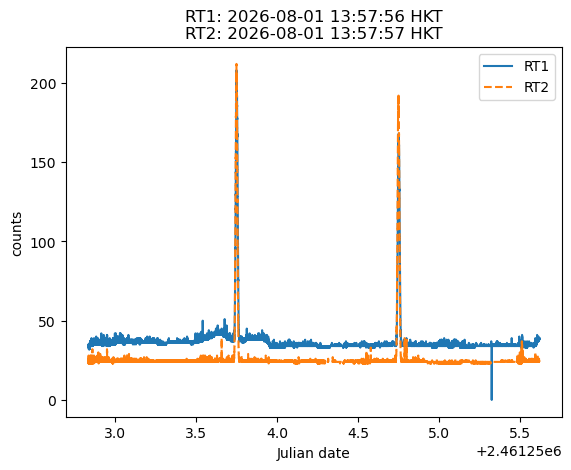

In [36]:
plt.plot(x_RT1,y_RT1,label='RT1')
plt.plot(x_RT2,y_RT2,label='RT2',ls='--')
#plt.xlim(0,200)
#plt.ylim(200,400)
plt.xlabel('Julian date')
plt.ylabel('counts')
#plt.title('31/07/2026')
plt.title("RT1: "+time_peak_rt1+"\n"+"RT2: "+time_peak_rt2)
plt.legend()
#plt.savefig('./20260731/uncalibrated.png')
plt.show()

In [37]:
# Cut only one peak RT1
x_RT1_cut = np.array(x_RT1[int(np.argmax(y_RT1)-8000):int(np.argmax(y_RT1)+8000)])
y_RT1_cut = np.array(y_RT1[int(np.argmax(y_RT1)-8000):int(np.argmax(y_RT1)+8000)])
# Cut only one peak RT2
x_RT2_cut = np.array(x_RT2[int(np.argmax(y_RT2)-8000):int(np.argmax(y_RT2)+8000)])
y_RT2_cut = np.array(y_RT2[int(np.argmax(y_RT2)-8000):int(np.argmax(y_RT2)+8000)])


###### TIME INFO #######
UTC Time:       2026-08-01 06:00:02.924
Hong Kong Time: 2026-08-01 14:00:02 HKT
### Gaussian Fit ###
Amplitude 161.9574572187576
Centre [Julian date] 2461253.750033845
Sigma [Days] -0.005492463998446675
Sigma [min] -7.9091481577632115
Background floor [adu] 38.74634608243448
FWHM [days] 0.0129337640728222
FWHM [min] 18.624620264863967
Estimated antenna beam with 0.25 deg/min 4.656155066215992


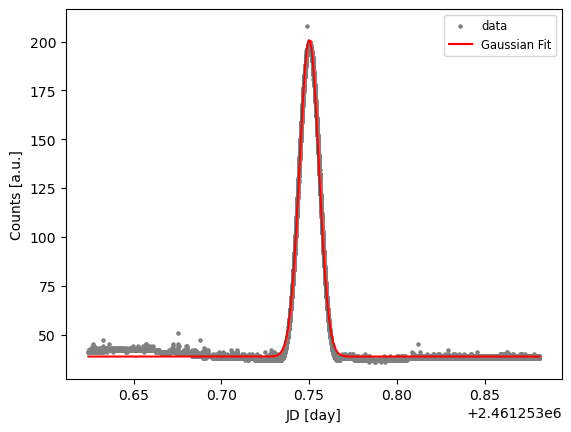

In [38]:
Amp_adu_rt1, centre_jd_rt1, sigma_jd_rt1, floor_adu_rt1, fwhm_day_rt1 =  gauss_fit(x_RT1_cut,y_RT1_cut,verbose=True,plot=True)

###### TIME INFO #######
UTC Time:       2026-08-01 05:57:57.330
Hong Kong Time: 2026-08-01 13:57:57 HKT
### Gaussian Fit ###
Amplitude 183.97269780545105
Centre [Julian date] 2461253.7485802057
Sigma [Days] 0.0055167761052510415
Sigma [min] 7.9441575915615
Background floor [adu] 24.186843208255922
FWHM [days] 0.012991014708167258
FWHM [min] 18.707061179760853
Estimated antenna beam with 0.25 deg/min 4.676765294940213


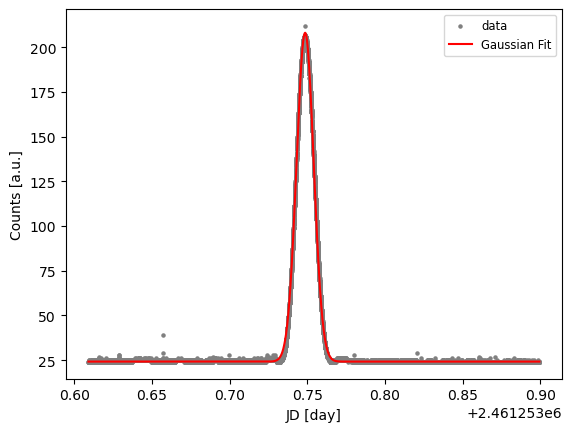

In [39]:
Amp_adu_rt2, centre_jd_rt2, sigma_jd_rt2, floor_adu_rt2, fwhm_day_rt2 =  gauss_fit(x_RT2_cut,y_RT2_cut,verbose=True,plot=True)

In [40]:
time_peak_rt1,time_peak_rt1

('2026-08-01 13:57:56 HKT', '2026-08-01 13:57:56 HKT')

In [41]:
time_peak_rt1_str =time_peak_rt1[2:4]+time_peak_rt1[5:7]+time_peak_rt1[8:10]
time_peak_rt2_str =time_peak_rt2[2:4]+time_peak_rt2[5:7]+time_peak_rt2[8:10]

In [42]:
# it only gets the day so RT1 and Rt2 are the same
f14 = get_solar_flux_on_date(time_peak_rt1_str,verbose=True)

Daytime Solar Average (1.4 GHz): 88.76 SFU
Raw 24-Hour Average (1.4 GHz):   86.06 SFU




In [43]:
K_RT1 = get_conversion_K(x_RT1,y_RT1,amp_adu=Amp_adu_rt1,solar_flux_sfu=f14)
print('Conversion factor between ADU to Antenna temperature (RT1): ',K_RT1)

K_RT2 = get_conversion_K(x_RT2,y_RT2,amp_adu=Amp_adu_rt2,solar_flux_sfu=f14)
print('Conversion factor between ADU to Antenna temperature (RT1): ',K_RT2)

Conversion factor between ADU to Antenna temperature (RT1):  8.42169456455506
Conversion factor between ADU to Antenna temperature (RT1):  7.413905723069503


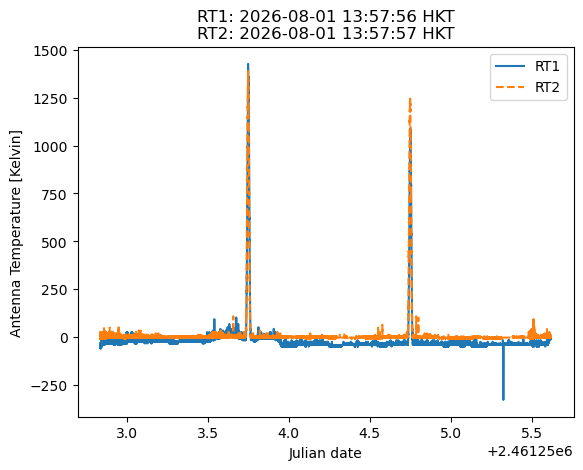

In [44]:
plt.plot(x_RT1,K_RT1*(y_RT1-floor_adu_rt1),label='RT1')
plt.plot(x_RT2,K_RT2*(y_RT2-floor_adu_rt2),label='RT2',ls='--')
#plt.xlim(0,200)
#plt.ylim(200,400)
plt.xlabel('Julian date')
plt.ylabel('Antenna Temperature [Kelvin]')
plt.title("RT1: "+time_peak_rt1+"\n"+"RT2: "+time_peak_rt2)
#plt.savefig('./20260731/calibrated_fitsun2807.png')
plt.legend()
plt.show()

